#Master Rating
***stop arguing with your friends about which move is better when playing backgammon, let the AI settle the problem***


# 1) Data loading: HuggingFace Dataset using `huggingface_hub`

First, we need to install the `huggingface_hub` library if it's not already installed.

In [ ]:

# Install huggingface_hub library
!pip install huggingface_hub

In [ ]:
from huggingface_hub import login
login()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Now, we can use the `hf_hub_download` function to download specific files from the dataset. Since the backgammon dataset has `.zip` files, we will download the main zip file.

In [ ]:
from huggingface_hub import hf_hub_download
import os
import zipfile

# Define the repository ID and the specific file to download
repo_id = "ArkadiumInc/ArkadiumBackgammon" # Updated repository ID based on user's input
filename = "Arkadium_Backgammon_full_data_gamelogs_001.zip"
local_dir = "/content/backgammon_huggingface"

# Create the local directory if it doesn't exist
os.makedirs(local_dir, exist_ok=True)

print(f"Downloading {filename} from {repo_id}...")
# Download the file
downloaded_file_path = hf_hub_download(
    repo_id=repo_id,
    filename=filename,
    cache_dir=local_dir,
    repo_type="dataset" # Specify repo_type as 'dataset'
)

print(f"File downloaded to: {downloaded_file_path}")

# Extract the zip file
EXTRACT_DIR = "/content/backgammon_huggingface_extracted"
os.makedirs(EXTRACT_DIR, exist_ok=True)

print(f"Extracting '{filename}' to '{EXTRACT_DIR}'...")
with zipfile.ZipFile(downloaded_file_path, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print(f"'{filename}' extracted to '{EXTRACT_DIR}'")
print("Contents of the extracted directory (first 5 files):")
print(os.listdir(EXTRACT_DIR)[:5])

Arkadium_Backgammon_full_data_gamelogs_0(…):   0%|          | 0.00/10.2M [00:00<?, ?B/s]

File downloaded to: /content/backgammon_huggingface/datasets--ArkadiumInc--ArkadiumBackgammon/snapshots/36e4fa908f3f149bbf85733ab0d20f2de6025a92/Arkadium_Backgammon_full_data_gamelogs_001.zip
Extracting 'Arkadium_Backgammon_full_data_gamelogs_001.zip' to '/content/backgammon_huggingface_extracted'...
'Arkadium_Backgammon_full_data_gamelogs_001.zip' extracted to '/content/backgammon_huggingface_extracted'
Contents of the extracted directory (first 5 files):
['1206123.mat', '1204001.mat', '1204994.mat', '1206788.mat', '1201658.mat']


The `.mat` files contain the detailed game logs. We'll use `scipy.io.loadmat` to load these files into Python. Let's load one sample `.mat` file and inspect its contents to understand the data structure.

In [ ]:
import scipy.io
import os

# Get a list of all .mat files in the extracted directory
mat_files = [f for f in os.listdir(EXTRACT_DIR) if f.endswith('.mat')]

if not mat_files:
    print(f"No .mat files found in {EXTRACT_DIR}")
else:
    # Load the first .mat file as a sample
    sample_mat_file_path = os.path.join(EXTRACT_DIR, '1205794.mat')
    print(f"Loading sample .mat file: {sample_mat_file_path}")

    # Attempt to read as text instead of .mat binary
    try:
        with open(sample_mat_file_path, 'r', encoding='utf-8') as f:
            content = f.read()
        print("\n--- Sample .mat file content (first 500 chars) ---\n")
        print(content[:])
        print("\n--- End of sample content ---\n")
        print("It appears these .mat files are text-based game logs, not binary MATLAB files.\n")
        print("We will need to parse them as text.")
    except Exception as e:
        print(f"Failed to read as text: {e}")
        print("Attempting to load as binary .mat file (if it was an actual MATLAB file):")
        try:
            mat_data = scipy.io.loadmat(sample_mat_file_path)
            print("\nKeys in the .mat file:")
            for key in mat_data.keys():
                print(f"- {key}")
            if 'logs' in mat_data:
                print(mat_data['logs'][:5])
            else:
                print("Could not find a common data key. Please inspect `mat_data.keys()` to find relevant data.")
                print(mat_data[list(mat_data.keys())[0]])
        except ValueError as ve:
            print(f"Original error loading as .mat: {ve}")
            print("The file is likely not a standard MATLAB .mat file.")
        except Exception as other_e:
            print(f"An unexpected error occurred while loading as .mat: {other_e}")

Loading sample .mat file: /content/backgammon_huggingface_extracted/1205794.mat

--- Sample .mat file content (first 500 chars) ---

; [Place "Arkadium"]
; [Player 1 "pl1"]
; [Player 2 "pl2"]
; [EventDate "2025.05.02"]
; [EventTime "23.16"]
; [CubeLimit "64"]
; [FF "4"]
; [CA "UTF-8"]
; [GN "Backgammon"]
; [GM "6"]
; [RU "Cube match"]
; [GP "bec46db9-5c26-c542-3b71-4b08a2fa8133"]
; [RE "void"]
; [C ""]

 7 point match

 Game 1
 pl1 : 0                   pl2 : 0
  1)                             25: 13/8 24/22
  2) 42: 8/4 6/4                 15: 13/8 24/23
  3) 12: 24/22 22/21             63: 22/16 16/13
  4) 53: 24/21 13/8              62: 8/2 13/11
  5) 66: 8/2* 8/2 13/7 13/7      32: 25/22 13/11
  6) 55: 8/3* 13/8 8/3 13/8      63:
  7) 11: 6/5 6/5 21/20 21/20     36:
  8) 65: 20/15 15/9              21: 25/24 8/6
  9) 24: 20/16 8/6               52: 6/1 8/6
 10) 63: 16/10 6/3               32: 6/3 3/1
 11) 42: 3/1* 9/5                43:
 12) 53: 10/5 5/2                64:
 13) 25:

#2) Preprocessing

###2.1)Initial backgammon Board


In [ ]:
def initial_board():
    """
    Standard backgammon starting position.

    Board layout:
        0-23  : board points
        24    : P1 bar
        25    : P2 bar
        26    : P1 borne off
        27    : P2 borne off

    Positive numbers  -> P1 checkers
    Negative numbers  -> P2 checkers

    Point mapping:
        index 0  = point 1
        index 23 = point 24
    """

    board = [0] * 28

    # ----- P1 -----
    board[23] = 2   # point 24
    board[12] = 5   # point 13
    board[7]  = 3   # point 8
    board[5]  = 5   # point 6

    # ----- P2 -----
    board[0]  = -2  # point 1
    board[11] = -5  # point 12
    board[16] = -3  # point 17
    board[18] = -5  # point 19

    return board

In [ ]:
BAR_P1 = 24
BAR_P2 = 25
OFF_P1 = 26
OFF_P2 = 27
def point_to_index(point, player):
  """ Convert log point -> internal board index. """
  if player == "P1":
   return point - 1
  return 24 - point

###2.2)parsing the text game logs

In [ ]:
import re

def split_games(text):
    games = re.split(r'\n\s*Game \d+\n', text)
    # Filter out games that do not contain the word "Win"
    filtered_games = [g.strip() for g in games if g.strip() and "Win" in g]
    return filtered_games

In [ ]:
import re

def parse_turn_line(line):
    match_turn_num = re.match(r'^\s*\d+\)', line)
    if not match_turn_num:
        return None, None # Not a recognized turn line format

    # Keep leading spaces for correct splitting later
    content_after_turn_num = line[match_turn_num.end():]

    p1_section_str = None
    p2_section_str = None

    # Define patterns for the start of any player action block (dice roll or keyword)
    action_start_pattern_keywords = r'(?:\d{2}:|Doubles|Takes|Drops|Wins)'

    # Find all potential action starts in the remaining content
    action_starts = [m.start() for m in re.finditer(action_start_pattern_keywords, content_after_turn_num)]

    if not action_starts:
        # No action block found at all in the content after the turn number
        return None, None

    if len(action_starts) == 1:
        # Only one action block found. This could be P1's move, or P2's move if P1 had none.
        first_action_start_idx = action_starts[0]
        leading_whitespace = content_after_turn_num[:first_action_start_idx]

        if re.match(r'^\s{3,}', leading_whitespace): # If 3 or more spaces, it's likely P2's move
            p1_section_str = None
            p2_section_str = content_after_turn_num[first_action_start_idx:].strip()
        else:
            # Otherwise, it's P1's move (or P1 had some action followed by nothing for P2)
            p1_section_str = content_after_turn_num.strip()
            p2_section_str = None
    else:
        # Two or more action blocks found. The first belongs to P1, the second (and subsequent) to P2.
        split_index = action_starts[1] # The start index of the second action block

        p1_section_str = content_after_turn_num[:split_index].strip()
        p2_section_str = content_after_turn_num[split_index:].strip()

    # Ensure empty strings become None for consistency
    if p1_section_str == '':
        p1_section_str = None
    if p2_section_str == '':
        p2_section_str = None

    return p1_section_str, p2_section_str

In [ ]:
import re

def parse_action_block(block):
    """
    Returns structured action:
    - move: dice + list of (src, dst, hit)
    - double / take / drop / win
    """

    if block is None:
        return None

    block = block.strip()

    # -------------------------
    # cube actions
    # -------------------------
    if block.startswith("Doubles"):
        value = re.search(r'(\d+)', block)
        return {
            "type": "double",
            "value": int(value.group(1)) if value else None
        }

    if block.startswith("Drops"):
        return {"type": "drop"}

    if block.startswith("Takes"):
        return {"type": "take"}

    if block.startswith("Wins"):
        value = re.search(r'(\d+)', block)
        return {
            "type": "win",
            "points": int(value.group(1)) if value else 1
        }

    # -------------------------
    # normal move parsing
    # -------------------------
    m = re.match(r'(\d)(\d):\s*(.*)', block)
    if not m:
        return None

    d1 = int(m.group(1))
    d2 = int(m.group(2))

    moves_str = m.group(3).strip()

    moves = []

    if moves_str:
        for mv in moves_str.split():

            hit = '*' in mv
            mv = mv.replace('*', '')

            if '/' in mv:
                src, dst = mv.split('/')

                moves.append({
                    "src": int(src),
                    "dst": int(dst),
                    "hit": hit
                })

    return {
        "type": "move",
        "dice": (d1, d2),
        "moves": moves
    }

In [ ]:
import re

def parse_player_section(section):
  """
  Parse one player's section.
  Returns:
    { "dice": (d1, d2) or None,
      "moves": [(from,to,is_hit), ...],
      "action": str or None,
      "points": int or None
    }
  """

  if not section:
    return None

  result = {
      "dice": None,
      "moves": [],
      "action": None,
      "points": None
  }

  s = section.strip()

  # -----------------------------------
  # Case: Doubles => N
  # -----------------------------------
  m = re.match(r'^Doubles\s*=>\s*(\d+)', s)
  if m:
    result["action"] = "double"
    result["points"] = int(m.group(1))
    return result

  # -----------------------------------
  # Case: Takes
  # -----------------------------------
  if s.startswith("Takes"):
    result["action"] = "take"
    return result

  # -----------------------------------
  # Case: Drops
  # -----------------------------------
  if s.startswith("Drops"):
    result["action"] = "drop"
    return result

  # -----------------------------------
  # Case: Wins N point(s)
  # -----------------------------------
  m = re.match(r'^Wins\s+(\d+)', s)
  if m:
    result["action"] = "win"
    result["points"] = int(m.group(1))
    return result

  # -----------------------------------
  # Case: dice + moves
  # Example:
  #   46: 8/2 6/2
  #   22:
  # -----------------------------------
  m = re.match(r'^(\d)(\d):\s*(.*)$', s)
  if m:
    d1 = int(m.group(1))
    d2 = int(m.group(2))
    moves_text = m.group(3).strip()

    result["dice"] = (d1, d2)

    if moves_text:
      tokens = moves_text.split()
      for token in tokens:
        move_match = re.match(r'(\d+)/(\d+)(\*)?', token)
        if move_match:
          src = int(move_match.group(1))
          dst = int(move_match.group(2))
          is_hit = bool(move_match.group(3))
          result["moves"].append(
              (src, dst, is_hit)
          )
    return result
  return result

In [ ]:
def apply_single_move(board, player, src, dst, is_hit=None):

    sign = 1 if player == "P1" else -1
    opponent_sign = -sign

    # -------------------------
    # source index
    # -------------------------
    if src == 25:
        src_idx = BAR_P1 if player == "P1" else BAR_P2
    else:
        src_idx = point_to_index(src, player)

    # -------------------------
    # destination index
    # -------------------------
    if dst == 0:
        dst_idx = OFF_P1 if player == "P1" else OFF_P2
    else:
        dst_idx = point_to_index(dst, player)

    # -------------------------
    # remove checker from source
    # -------------------------
    board[src_idx] -= sign

    # -------------------------
    # auto-detect hit
    # -------------------------
    hit_detected = board[dst_idx] == opponent_sign

    if hit_detected:

        # remove opponent blot
        board[dst_idx] -= opponent_sign

        # send opponent to bar
        if player == "P1":
            board[BAR_P2] -= 1
        else:
            board[BAR_P1] += 1

    # -------------------------
    # place checker
    # -------------------------
    board[dst_idx] += sign

    return board

In [ ]:
from copy import deepcopy

def apply_moves(board, player, moves):

    board = deepcopy(board)

    for src, dst in moves:
        apply_single_move(board, player, src, dst)

    return board

In [ ]:
from copy import deepcopy

def apply_moves_inference(board, player, moves_sequence):

    board = deepcopy(board)

    # Check if the sequence is a flattened list of integers (e.g., [src, dst, src, dst, ...])
    # This is indicated if the first element is an integer and not a tuple/list itself.
    if moves_sequence and isinstance(moves_sequence[0], int):
        # Iterate in pairs (src, dst)
        for i in range(0, len(moves_sequence), 2):
            src = moves_sequence[i]
            dst = moves_sequence[i+1]
            apply_single_move(board, player, src, dst)
    else:
        # Otherwise, assume it's a list of (src, dst) tuples or similar iterable pairs
        for src, dst in moves_sequence:
            apply_single_move(board, player, src, dst)

    return board

In [ ]:
from copy import deepcopy

def apply_turn(board, action, player):

    if action is None:
        return board

    if action["type"] != "move":
        return board

    # Store the original board state for this turn.
    # If any move is illegal, we'll revert to this state.
    original_board_for_turn = deepcopy(board)

    current_board_state = board

    for mv in action["moves"]:
        # apply_single_move creates its own copy, so no need for deepcopy(current_board_state) here
        next_board_state = apply_single_move(
            board=current_board_state,
            player=player,
            src=mv["src"],
            dst=mv["dst"],
            is_hit=mv["hit"]
        )

        if next_board_state is None:
            # If an illegal move is detected, the entire sequence for this turn is invalid.
            # Return the board state as it was *before* this turn started.
            return original_board_for_turn

        current_board_state = next_board_state

    # If all moves were successfully applied, return the final board state for the turn
    return current_board_state

In [ ]:
import re
from copy import deepcopy

def process_game(game_text, game_id):

    board_state_before_current_turn = initial_board() # This represents the board state before the current player's move.

    rows = []

    winner = None
    turn_index = 0

    lines = game_text.splitlines()

    for line in lines:

        line = line.rstrip()

        # skip empty lines
        if not line:
            continue

        # only process turn lines like "1)"
        if not re.match(r'^\s*\d+\)', line):
            continue

        # split into P1 / P2 sections
        p1_raw, p2_raw = parse_turn_line(line)

        player_sections = [
            ("P1", p1_raw),
            ("P2", p2_raw)
        ]

        for player, raw_block in player_sections:

            if raw_block is None:
                continue

            action = parse_action_block(raw_block)

            if action is None:
                continue

            # -------------------------------------------------
            # base row structure
            # -------------------------------------------------
            row = {
                "game_id": game_id,
                "turn": turn_index,
                "player": player,
                "dice": None,
                "move": None,
                "board_before_move": deepcopy(board_state_before_current_turn), # Capture board BEFORE move
                "board_after_move": None, # This will be the new 'board' column, which was previously named 'board'
                "winner": None,
                "action": action["type"]
            }

            # =================================================
            # MOVE ACTION
            # =================================================
            if action["type"] == "move":

                dice = action["dice"]

                # APPLY FULL TURN THROUGH ENGINE
                # This `board_state_before_current_turn` is correctly the state before THIS player's move.
                board_state_after_current_turn = apply_turn(board_state_before_current_turn, action, player)

                row["dice"] = f"{dice[0]},{dice[1]}"

                # flatten moves for dataset logging
                if action["moves"]:
                    flat_moves = []
                    for mv in action["moves"]:
                        flat_moves.extend([mv["src"], mv["dst"]])

                    row["move"] = ",".join(map(str, flat_moves))
                else:
                    row["move"] = ""

                row["board_after_move"] = deepcopy(board_state_after_current_turn)
                board_state_before_current_turn = board_state_after_current_turn # Update for the next player/turn

            # =================================================
            # DOUBLE, TAKE, DROP, WIN actions
            # These actions don't change checker positions, so board_before_move == board_after_move.
            # =================================================
            elif action["type"] in ["double", "take", "drop", "win"]:
                row["board_after_move"] = deepcopy(board_state_before_current_turn) # Board state remains the same for these actions

            if action["type"] == "double":
                row["cube_value"] = action.get("value")
            elif action["type"] == "win":
                winner = player
                row["points"] = action.get("points", 1)
                row["winner"] = winner

            rows.append(row)

            turn_index += 1

    # =====================================================
    # BACKFILL WINNER FOR ALL ROWS
    # =====================================================
    if winner is not None:
        for r in rows:
            r["winner"] = winner

    return rows

In [ ]:
def process_file(text, file_name):

    games = split_games(text)
    #print(f"Found {len(games)-1} games in {file_name}")

    all_rows = []

    for i, game_text in enumerate(games):
        game_id = f"{file_name}{i}"
        rows = process_game(game_text, game_id)
        all_rows.extend(rows)

    return all_rows

###2.3)Applying the parsing functions to all the games

In [ ]:
import pandas as pd
from tqdm.notebook import tqdm

all_game_data = []

# mat_files is already defined from previous steps, containing all .mat filenames
for gamename in tqdm(mat_files, desc="Processing game files"):
    file_path = os.path.join(EXTRACT_DIR, gamename)
    with open(file_path, 'r', encoding='utf-8') as f:
        text = f.read()

    game_rows = process_file(text, gamename)
    all_game_data.extend(game_rows)

df = pd.DataFrame(all_game_data)
print(f"DataFrame created with {len(df)} rows from all games.")

Processing game files:   0%|          | 0/8472 [00:00<?, ?it/s]

DataFrame created with 981192 rows from all games.


In [ ]:
df

,game_id,turn,player,dice,move,board_before_move,board_after_move,winner,action,cube_value,points
0,1203430.mat0,0,P2,"2,6","24,22,22,16","[-2, 0, 0, 0, 0, 5, 0, 3, 0, 0, 0, -5, 5, 0, 0...","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ...",None,move,NaN,NaN
1,1203430.mat0,1,P1,"6,6","13,7,13,7,24,18,24,18","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ...",None,move,NaN,NaN
2,1203430.mat0,2,P2,"2,1","16,15,15,13","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0...",None,move,NaN,NaN
3,1203430.mat0,3,P1,"1,5","13,8,8,7","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0...","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0...",None,move,NaN,NaN
4,1203430.mat0,4,P2,"3,5","24,21,21,16","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0...","[0, 0, 0, 0, 0, 5, 3, 3, -1, 0, 0, -6, 2, 0, 0...",None,move,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
981187,1200223.mat4,26,P1,"2,4","8,4,6,4","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,...",None,move,NaN,NaN
981188,1200223.mat4,27,P2,"5,4",,"[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,...","[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,...",None,move,NaN,NaN
981189,1200223.mat4,28,P1,"4,5","6,2,13,8","[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,...","[2, 2, 0, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0,...",None,move,NaN,NaN
981190,1200223.mat4,29,P2,"5,3","25,22,7,2","[2, 2, 0, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0,...","[2, 2, -1, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0...",None,move,NaN,NaN



###2.4)Generating legal moves

In [ ]:
from copy import deepcopy

# =========================================================
# DICE HANDLING
# =========================================================

def expand_dice(dice):
    d1, d2 = dice
    if d1 == d2:
        return [d1] * 4
    return [d1, d2]


# =========================================================
# HOME BOARD CHECK
# =========================================================

def all_in_home_board(board, player):
    """
    P1 home: points 1-6   (indices 0-5)
    P2 home: points 1-6 in LOGICAL SPACE
             internally indices 18-23
    """

    if player == "P1":

        # points 7-24
        for i in range(6, 24):
            if board[i] > 0:
                return False

        # P1 bar
        if board[BAR_P1] > 0:
            return False

    else:

        # points 7-24 in P2 logical space
        # internally = indices 0-17
        for i in range(0, 18):
            if board[i] < 0:
                return False

        # P2 bar
        if board[BAR_P2] < 0:
            return False

    return True


# =========================================================
# LANDING CHECK
# =========================================================

def can_land(board, player, target_idx):

    if not (0 <= target_idx <= 23):
        return False

    if player == "P1":
        return board[target_idx] >= -1
    else:
        return board[target_idx] <= 1


# =========================================================
# BEAR-OFF VALIDATION
# =========================================================

def highest_occupied_point(board, player):
    """
    Returns highest occupied logical point
    for the player inside home board.

    P1 logical points: 1..6
    P2 logical points: 1..6
    """

    if player == "P1":

        for point in range(6, 0, -1):
            idx = point - 1

            if board[idx] > 0:
                return point

    else:

        for point in range(6, 0, -1):

            # P2 logical point -> internal idx
            idx = 24 - point

            if board[idx] < 0:
                return point

    return None


def can_bear_off(board, player, src_log_point, die):
    """
    Official bear-off rule.

    Exact roll:
        point == die

    Oversized roll:
        allowed ONLY if no checker exists
        on higher points.
    """

    # exact roll
    if src_log_point == die:
        return True

    # oversized roll
    if src_log_point < die:

        highest_point = highest_occupied_point(board, player)

        return highest_point == src_log_point

    return False


# =========================================================
# SINGLE MOVE GENERATION
# =========================================================

def get_single_moves(board, player, die):

    moves = []

    sign = 1 if player == "P1" else -1

    # =====================================================
    # BAR MOVES
    # =====================================================

    bar_idx = BAR_P1 if player == "P1" else BAR_P2

    if board[bar_idx] * sign > 0:

        # unified logical system
        target_log_point = 25 - die

        target_idx = point_to_index(target_log_point, player)

        if can_land(board, player, target_idx):
            moves.append((25, target_log_point))

        return moves

    # =====================================================
    # NORMAL MOVES
    # =====================================================

    if player == "P1":

        iterator = range(23, -1, -1)

    else:

        iterator = range(0, 24)

    for src_idx in iterator:

        if board[src_idx] * sign <= 0:
            continue

        # ---------------------------------------------
        # INTERNAL -> LOGICAL
        # ---------------------------------------------

        if player == "P1":
            src_log_point = src_idx + 1
        else:
            src_log_point = 24 - src_idx

        target_log_point = src_log_point - die

        # =================================================
        # BEAR OFF
        # =================================================

        if target_log_point <= 0:

            if all_in_home_board(board, player):

                if can_bear_off(
                    board,
                    player,
                    src_log_point,
                    die
                ):
                    moves.append((src_log_point, 0))

        # =================================================
        # NORMAL BOARD MOVE
        # =================================================

        else:

            target_idx = point_to_index(
                target_log_point,
                player
            )

            if can_land(board, player, target_idx):

                moves.append(
                    (src_log_point, target_log_point)
                )

    return moves


# =========================================================
# RECURSIVE MOVE GENERATION
# =========================================================

def generate_moves_recursive(board, player, dice_list):

    if not dice_list:
        return [[]]

    die = dice_list[0]

    possible_moves = get_single_moves(
        board,
        player,
        die
    )

    # -----------------------------------------------------
    # NO MOVES FOR THIS DIE
    # -----------------------------------------------------

    if not possible_moves:
        return generate_moves_recursive(
            board,
            player,
            dice_list[1:]
        )

    all_sequences = []

    # -----------------------------------------------------
    # TRY ALL MOVES
    # -----------------------------------------------------

    for move_tuple in possible_moves:

        src, dst = move_tuple

        temp_board = deepcopy(board)

        apply_single_move(
            board=temp_board,
            player=player,
            src=src,
            dst=dst,
            is_hit=False
        )

        next_sequences = generate_moves_recursive(
            temp_board,
            player,
            dice_list[1:]
        )

        for seq in next_sequences:
            all_sequences.append(
                [move_tuple] + seq
            )

    return all_sequences

In [ ]:
#if only one dice can move , you must move the bigger die
def filter_best_sequences(sequences):
    if not sequences:
        return []

    # 1. Max number of moves (use most dice)
    max_len = max(len(seq) for seq in sequences)
    sequences = [s for s in sequences if len(s) == max_len]

    # 2. Max total distance (prefer higher die)
    def total_pips(seq):
        return sum(abs(f - t) for f, t in seq)

    max_pip = max(total_pips(s) for s in sequences)
    sequences = [s for s in sequences if total_pips(s) == max_pip]

    return sequences

In [ ]:
def generate_legal_moves(board, player, dice):

    dice_list = expand_dice(dice)

    seq1 = generate_moves_recursive(
        deepcopy(board),
        player,
        dice_list
    )

    seq2 = generate_moves_recursive(
        deepcopy(board),
        player,
        dice_list[::-1]
    )

    all_moves = seq1 + seq2

    # remove exact duplicates only
    unique = []
    seen = set()

    for seq in all_moves:     ###here

        key = tuple(sorted(seq))
        if key not in seen:
            seen.add(key)
            unique.append(seq)

    return unique

In [ ]:
###Testing generate moves
board=[3,4,2,0,0,0,0,0,0,-1,0,-2,0,-1,0,0,-2,0,-5,-1,0,0,-1,-2,0,0,6,0]
dice = (3,3)
player = "P1" # Specify the player for whom to generate moves
dm=(generate_legal_moves(board, player, dice))
dm

[[(3, 0), (3, 0), (2, 0), (2, 0)]]

###2.5)Before appling generating the legal moves , we clean the dataframe

In [ ]:
print(f"Original df_loaded rows: {len(df)}")

# Filter out rows where 'dice' or 'move' are None
df_cleaned = df[df['dice'].notna() & df['move'].notna()].copy()

print(f"df_cleaned rows after filtering for dice and move: {len(df_cleaned)}")

# Drop unnecessary columns
columns_to_drop = ['winner', 'action', 'cube_value', 'points']
df_cleaned = df_cleaned.drop(columns=columns_to_drop, errors='ignore')

print(f"df_cleaned columns after dropping: {df_cleaned.columns.tolist()}")

df_cleaned = df_cleaned[df_cleaned['move'].apply(lambda x: len(x) > 0)].copy()

df_cleaned  # Update df_loaded to the cleaned version

Original df_loaded rows: 981192
df_cleaned rows after filtering for dice and move: 953525
df_cleaned columns after dropping: ['game_id', 'turn', 'player', 'dice', 'move', 'board_before_move', 'board_after_move']


,game_id,turn,player,dice,move,board_before_move,board_after_move
0,1203430.mat0,0,P2,"2,6","24,22,22,16","[-2, 0, 0, 0, 0, 5, 0, 3, 0, 0, 0, -5, 5, 0, 0...","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ..."
1,1203430.mat0,1,P1,"6,6","13,7,13,7,24,18,24,18","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ..."
2,1203430.mat0,2,P2,"2,1","16,15,15,13","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0..."
3,1203430.mat0,3,P1,"1,5","13,8,8,7","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0...","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0..."
4,1203430.mat0,4,P2,"3,5","24,21,21,16","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0...","[0, 0, 0, 0, 0, 5, 3, 3, -1, 0, 0, -6, 2, 0, 0..."
...,...,...,...,...,...,...,...
981186,1200223.mat4,25,P2,"6,3","7,1,5,2","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0..."
981187,1200223.mat4,26,P1,"2,4","8,4,6,4","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,..."
981189,1200223.mat4,28,P1,"4,5","6,2,13,8","[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,...","[2, 2, 0, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0,..."
981190,1200223.mat4,29,P2,"5,3","25,22,7,2","[2, 2, 0, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0,...","[2, 2, -1, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0..."


###2.6)Applying the legal move generator to all the row in the df

In [ ]:
from tqdm.notebook import tqdm
import pandas as pd
tqdm.pandas() # Initialize tqdm.pandas to add .progress_apply to DataFrames

def get_legal_moves_for_row(row):

    board = row['board_before_move']
    player = row['player']
    # Convert dice string 'd1,d2' to tuple (d1, d2)
    dice = tuple(int(x) for x in row['dice'].split(','))
    return generate_legal_moves(board, player, dice)

# Apply the function to create the new 'legal_moves' column with a progress bar
df_cleaned['legal_moves'] = df_cleaned.progress_apply(get_legal_moves_for_row, axis=1)

print("Added 'legal_moves' column to the DataFrame.")


  0%|          | 0/875281 [00:00<?, ?it/s]

Added 'legal_moves' column to the DataFrame.


In [ ]:
df_cleaned

,game_id,turn,player,dice,move,board_before_move,board_after_move,legal_moves
0,1203430.mat0,0,P2,"2,6","24,22,22,16","[-2, 0, 0, 0, 0, 5, 0, 3, 0, 0, 0, -5, 5, 0, 0...","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ...","[[(24, 22), (24, 18)], [(24, 22), (22, 16)], [..."
1,1203430.mat0,1,P1,"6,6","13,7,13,7,24,18,24,18","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ...","[[(24, 18), (24, 18), (13, 7), (13, 7)], [(24,..."
2,1203430.mat0,2,P2,"2,1","16,15,15,13","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0...","[[(24, 22), (22, 21)], [(24, 22), (16, 15)], [..."
3,1203430.mat0,3,P1,"1,5","13,8,8,7","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0...","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0...","[[(8, 7), (18, 13)], [(8, 7), (13, 8)], [(8, 7..."
4,1203430.mat0,4,P2,"3,5","24,21,21,16","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0...","[0, 0, 0, 0, 0, 5, 3, 3, -1, 0, 0, -6, 2, 0, 0...","[[(24, 21), (21, 16)], [(24, 21), (13, 8)], [(..."
...,...,...,...,...,...,...,...,...
981186,1200223.mat4,25,P2,"6,3","7,1,5,2","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[[(21, 15), (18, 15)], [(21, 15), (7, 4)], [(2..."
981187,1200223.mat4,26,P1,"2,4","8,4,6,4","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,...","[[(13, 11), (13, 9)], [(13, 11), (8, 4)], [(13..."
981189,1200223.mat4,28,P1,"4,5","6,2,13,8","[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,...","[2, 2, 0, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0,...","[[(13, 9), (13, 8)], [(13, 9), (9, 4)], [(13, ..."
981190,1200223.mat4,29,P2,"5,3","25,22,7,2","[2, 2, 0, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0,...","[2, 2, -1, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0...","[[(25, 22)], [(25, 22), (18, 13)], [(25, 22), ..."


###2.7)Genarating Labels(chosen_idx) for chosen move by players from a list of all the legal_moves

In [ ]:
def parse_move(move_str):

    # Empty move
    if move_str is None or move_str == "":
        return []

    nums = [int(x) for x in move_str.split(",")]

    return [
        (nums[i], nums[i+1])
        for i in range(0, len(nums), 2)
    ]

df_loaded["move"] = df_loaded["move"].apply(parse_move)

In [ ]:
from collections import Counter

# =========================================================
# Normalize as MULTISET (NOT order-based sorting)
# =========================================================
def normalize_sequence(seq):
    """
    Treat move sequence as a multiset:
    order does NOT matter, but duplicates DO matter.
    """
    return Counter(tuple(m) for m in seq)


# =========================================================
# Compute chosen_idx
# =========================================================
chosen_indices = []

for _, row in df_loaded.iterrows():

    # chosen move from human log
    chosen_move = normalize_sequence(row["move"])

    legal_moves = row["legal_moves"]

    chosen_idx = None

    # First, try to find an exact match (multiset equality)
    for idx, candidate_move in enumerate(legal_moves):
        if normalize_sequence(candidate_move) == chosen_move:
            chosen_idx = idx
            break

    # If no exact match, try a more lenient sub-multiset match
    # This implies the recorded move is a valid partial sequence of a full legal move.
    # Note: This might not strictly adhere to all backgammon rules (e.g., must use all pips if possible).
    if chosen_idx is None:
        for idx, candidate_move in enumerate(legal_moves):
            normalized_candidate = normalize_sequence(candidate_move)
            # Check if all elements of chosen_move (with their counts) are present in normalized_candidate
            if all(chosen_move[move] <= normalized_candidate.get(move, 0) for move in chosen_move):
                chosen_idx = idx
                break

    chosen_indices.append(chosen_idx)


# =========================================================
# Add to dataframe
# =========================================================
df_loaded["chosen_idx"] = chosen_indices

In [ ]:
df_loaded

,game_id,turn,player,dice,move,board_before_move,board_after_move,legal_moves,chosen_idx
0,1203430.mat0,0,P2,"2,6","[(24, 22), (22, 16)]","[-2, 0, 0, 0, 0, 5, 0, 3, 0, 0, 0, -5, 5, 0, 0...","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ...","[[(24, 22), (24, 18)], [(24, 22), (22, 16)], [...",1
1,1203430.mat0,1,P1,"6,6","[(13, 7), (13, 7), (24, 18), (24, 18)]","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ...","[[(24, 18), (24, 18), (13, 7), (13, 7)], [(24,...",0
2,1203430.mat0,2,P2,"2,1","[(16, 15), (15, 13)]","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0...","[[(24, 22), (22, 21)], [(24, 22), (16, 15)], [...",18
3,1203430.mat0,3,P1,"1,5","[(13, 8), (8, 7)]","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0...","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0...","[[(8, 7), (18, 13)], [(8, 7), (13, 8)], [(8, 7...",1
4,1203430.mat0,4,P2,"3,5","[(24, 21), (21, 16)]","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0...","[0, 0, 0, 0, 0, 5, 3, 3, -1, 0, 0, -6, 2, 0, 0...","[[(24, 21), (21, 16)], [(24, 21), (13, 8)], [(...",0
...,...,...,...,...,...,...,...,...,...
981186,1200223.mat4,25,P2,"6,3","[(7, 1), (5, 2)]","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[[(21, 15), (18, 15)], [(21, 15), (7, 4)], [(2...",9
981187,1200223.mat4,26,P1,"2,4","[(8, 4), (6, 4)]","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,...","[[(13, 11), (13, 9)], [(13, 11), (8, 4)], [(13...",9
981189,1200223.mat4,28,P1,"4,5","[(6, 2), (13, 8)]","[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,...","[2, 2, 0, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0,...","[[(13, 9), (13, 8)], [(13, 9), (9, 4)], [(13, ...",6
981190,1200223.mat4,29,P2,"5,3","[(25, 22), (7, 2)]","[2, 2, 0, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0,...","[2, 2, -1, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0...","[[(25, 22)], [(25, 22), (18, 13)], [(25, 22), ...",2


In [ ]:
# ============================================
# FINAL ML FORMAT NORMALIZATION
# ============================================

import ast
import pandas as pd
import numpy as np

# --------------------------------------------
# Helpers
# --------------------------------------------

def ensure_list(x):
    """
    Convert stringified lists into real Python lists.
    """
    if isinstance(x, str):
        return ast.literal_eval(x)
    return x


def normalize_board(board):
    """
    Ensure board is list[int] length 28
    """
    board = ensure_list(board)
    board = [int(v) for v in board]

    assert len(board) == 28, f"Board length != 28 : {len(board)}"

    return board


def normalize_player(player):
    """
    P1 -> 0
    P2 -> 1
    """
    if player == "P1":
        return 0
    elif player == "P2":
        return 1

    return int(player)


def normalize_dice(dice):
    """
    Ensure dice is list[int]
    Example:
        (4,3) -> [4,3]
    """
    dice = ensure_list(dice)

    return [int(d) for d in dice]


def normalize_legal_moves(moves):
    """
    Ensure legal_moves is:
        list[list[int]]

    Example:
        [
            [25,22,22,18],
            [13,9,9,5]
        ]
    """
    moves = ensure_list(moves) # This handles potential stringified lists

    normalized_sequences = []
    for sequence_of_tuples in moves: # Each sequence_of_tuples is like [(src1, dst1), (src2, dst2)]
        flattened_move_list = []
        for src_dst_tuple in sequence_of_tuples: # Each src_dst_tuple is like (src, dst)
            # Ensure src and dst are integers and flatten them
            flattened_move_list.append(int(src_dst_tuple[0]))
            flattened_move_list.append(int(src_dst_tuple[1]))
        normalized_sequences.append(flattened_move_list)

    return normalized_sequences


# --------------------------------------------
# Apply normalization
# --------------------------------------------

df_loaded["board_before_move"] = df_loaded["board_before_move"].apply(normalize_board)

df_loaded["player"] = df_loaded["player"].apply(normalize_player)

df_loaded["dice"] = df_loaded["dice"].apply(normalize_dice)

df_loaded["legal_moves"] = df_loaded["legal_moves"].apply(normalize_legal_moves)

df_loaded["chosen_idx"] = df_loaded["chosen_idx"].astype(int)

In [ ]:
df_cleaned

,game_id,turn,player,dice,move,board_before_move,board_after_move,legal_moves,chosen_idx
0,1203430.mat0,0,1,"[2, 6]","[(24, 22), (22, 16)]","[-2, 0, 0, 0, 0, 5, 0, 3, 0, 0, 0, -5, 5, 0, 0...","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ...","[[24, 22, 24, 18], [24, 22, 22, 16], [24, 22, ...",1
1,1203430.mat0,1,0,"[6, 6]","[(13, 7), (13, 7), (24, 18), (24, 18)]","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ...","[[24, 18, 24, 18, 13, 7, 13, 7], [24, 18, 24, ...",0
2,1203430.mat0,2,1,"[2, 1]","[(16, 15), (15, 13)]","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0...","[[24, 22, 22, 21], [24, 22, 16, 15], [24, 22, ...",18
3,1203430.mat0,3,0,"[1, 5]","[(13, 8), (8, 7)]","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0...","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0...","[[8, 7, 18, 13], [8, 7, 13, 8], [8, 7, 8, 3], ...",1
4,1203430.mat0,4,1,"[3, 5]","[(24, 21), (21, 16)]","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0...","[0, 0, 0, 0, 0, 5, 3, 3, -1, 0, 0, -6, 2, 0, 0...","[[24, 21, 21, 16], [24, 21, 13, 8], [24, 21, 8...",0
...,...,...,...,...,...,...,...,...,...
981186,1200223.mat4,25,1,"[6, 3]","[(7, 1), (5, 2)]","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[[21, 15, 18, 15], [21, 15, 7, 4], [21, 15, 6,...",9
981187,1200223.mat4,26,0,"[2, 4]","[(8, 4), (6, 4)]","[2, 1, 0, -1, 3, 5, -2, 2, 0, 0, 0, 0, 2, 0, 0...","[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,...","[[13, 11, 13, 9], [13, 11, 8, 4], [13, 11, 6, ...",9
981189,1200223.mat4,28,0,"[4, 5]","[(6, 2), (13, 8)]","[2, 1, 0, 2, 3, 4, -2, 1, 0, 0, 0, 0, 2, 0, 0,...","[2, 2, 0, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0,...","[[13, 9, 13, 8], [13, 9, 9, 4], [13, 9, 8, 3],...",6
981190,1200223.mat4,29,1,"[5, 3]","[(25, 22), (7, 2)]","[2, 2, 0, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0,...","[2, 2, -1, 2, 3, 3, -2, 2, 0, 0, 0, 0, 1, 0, 0...","[[25, 22], [25, 22, 18, 13], [25, 22, 7, 2], [...",2


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


###Max number of legal_moves and chosen_idx:

In [ ]:
print("max number of legal_moves:",df_loaded['legal_moves'].apply(len).max())
print("max number of chosen_idx:",df_loaded['chosen_idx'].max())

max number of legal_moves: 846
max number of chosen_idx: 627


#Save and Load the preprocessed dataframe

### Saving `df` to Google Drive (Pickle format)

I'll save the `df` DataFrame to your Google Drive as a pickle file (`.pkl`). This format is ideal because it preserves the exact data types of your columns, including lists and tuples, making it very straightforward to load back into a DataFrame later without needing to `eval()` or manually parse strings.

The file will be saved in your mounted Google Drive under `MyDrive/Colab Notebooks/colab_notebooks_data/`.

In [ ]:
import os

# Generalizing the output directory:
# Check if Google Drive is mounted, otherwise fallback to the local environment root
if os.path.exists('/content/drive/MyDrive/'):
    drive_path = '/content/drive/MyDrive/Colab Notebooks/'
else:
    print("Google Drive not detected. Saving to local runtime directory instead.")
    drive_path = './colab_notebooks_data/'

output_filename = 'backgammon_df_ready_for_ml.pkl'
full_output_path = os.path.join(drive_path, output_filename)

# Automatically create directory if it doesn't exist
os.makedirs(os.path.dirname(full_output_path), exist_ok=True)

print(f"Saving DataFrame to: {full_output_path}")
df_loaded.to_pickle(full_output_path)
print("DataFrame saved successfully!")

Saving DataFrame to: /content/drive/MyDrive/Colab Notebooks/backgammon_df_ready_for_ml.pkl
DataFrame saved successfully!


### Loading `df` from Google Drive

To load the DataFrame back in a new session or notebook, you can use the following code. Remember to run the `drive.mount('/content/drive')` cell first.

In [ ]:
import pandas as pd

import os

# Generalizing the input directory:
# Check if Google Drive is mounted, otherwise fallback to the local environment root
if os.path.exists('/content/drive/MyDrive/'):
    drive_path = '/content/drive/MyDrive/Colab Notebooks/'
else:
    print("Google Drive not detected. Loading from local runtime directory instead.")
    drive_path = './colab_notebooks_data/'

output_filename = 'backgammon_df_ready_for_ml.pkl'
full_input_path = os.path.join(drive_path, output_filename)

if not os.path.exists(full_input_path):
    raise FileNotFoundError(f"File not found at {full_input_path}. Please make sure you have run the saving step or uploaded the file to this path.")

print(f"Loading DataFrame from: {full_input_path}")
df_loaded = pd.read_pickle(full_input_path)

print("DataFrame loaded successfully!")
display(df_loaded.head())

Loading DataFrame from: /content/drive/MyDrive/Colab Notebooks/backgammon_df_ready_for_ml.pkl
DataFrame loaded successfully!


,game_id,turn,player,dice,move,board_before_move,board_after_move,legal_moves,chosen_idx
0,1203430.mat0,0,1,"[2, 6]","[(24, 22), (22, 16)]","[-2, 0, 0, 0, 0, 5, 0, 3, 0, 0, 0, -5, 5, 0, 0...","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ...","[[24, 22, 24, 18], [24, 22, 22, 16], [24, 22, ...",1
1,1203430.mat0,1,0,"[6, 6]","[(13, 7), (13, 7), (24, 18), (24, 18)]","[-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ...","[[24, 18, 24, 18, 13, 7, 13, 7], [24, 18, 24, ...",0
2,1203430.mat0,2,1,"[2, 1]","[(16, 15), (15, 13)]","[-1, 0, 0, 0, 0, 5, 2, 3, -1, 0, 0, -5, 3, 0, ...","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0...","[[24, 22, 22, 21], [24, 22, 16, 15], [24, 22, ...",18
3,1203430.mat0,3,0,"[1, 5]","[(13, 8), (8, 7)]","[-1, 0, 0, 0, 0, 5, 2, 3, 0, 0, 0, -6, 3, 0, 0...","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0...","[[8, 7, 18, 13], [8, 7, 13, 8], [8, 7, 8, 3], ...",1
4,1203430.mat0,4,1,"[3, 5]","[(24, 21), (21, 16)]","[-1, 0, 0, 0, 0, 5, 3, 3, 0, 0, 0, -6, 2, 0, 0...","[0, 0, 0, 0, 0, 5, 3, 3, -1, 0, 0, -6, 2, 0, 0...","[[24, 21, 21, 16], [24, 21, 13, 8], [24, 21, 8...",0


In [ ]:
#checking for specific game
#df_loaded[df_loaded['game_id'] == '1204743.mat0']
df_loaded.dtypes

,0
game_id,object
turn,int64
player,int64
dice,object
move,object
board_before_move,object
board_after_move,object
legal_moves,object
chosen_idx,int64


#3) Feature extraction and Splitting datafram for training and testing

In [ ]:
# Count how many times each unique move index was picked by the expert
move_counts = df_loaded["chosen_idx"].value_counts()

# Keep only moves that appear at least 3 times across your whole dataset
# This guarantees there's enough data to spread into Train, Val, and Test
valid_moves = move_counts[move_counts >= 3].index
df_clean = df_loaded[df_loaded["chosen_idx"].isin(valid_moves)].reset_index(drop=True)

# Now, apply a Global Label Encoder so all three models use identical class sizes (0 to C-1)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df_clean["encoded_label"] = le.fit_transform(df_clean["chosen_idx"])

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Split into Train and Temp (70% / 30%)
train_df, temp_df = train_test_split(df_clean, test_size=0.30, random_state=42, shuffle=True)

# 2. Split Temp into Val and Test (15% / 15%)
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, shuffle=True)

print(f"Training set:   {len(train_df)} rows")
print(f"Validation set: {len(val_df)} rows")
print(f"Test set:       {len(test_df)} rows")

Training set:   612608 rows
Validation set: 131273 rows
Test set:       131274 rows


In [ ]:
import pandas as pd
import numpy as np

def extract_flat_features(target_df):
    # Flatten the 28 board elements into standalone columns
    board_feats = pd.DataFrame(target_df["board_before_move"].tolist())
    player_feat = target_df[["player"]].reset_index(drop=True)
    dice_feats = pd.DataFrame(target_df["dice"].tolist(), columns=["dice_1", "dice_2"])

    # Combine into a single feature matrix X
    X = pd.concat([board_feats, player_feat, dice_feats], axis=1).values
    y = target_df["encoded_label"].values
    return X, y

# Generate training data matrices
X_train_flat, y_train_flat = extract_flat_features(train_df)
X_val_flat, y_val_flat = extract_flat_features(val_df)
X_test_flat, y_test_flat = extract_flat_features(test_df)


#4) Models

##Baseline Model


In [ ]:
def get_baseline_top_3(board_before, player_idx, legal_moves_list):
    """
    Evaluates all legal moves for a given board state based on a basic
    expert strategy heuristic and returns the top 3 best moves.

    player_idx: 0 for P1, 1 for P2.
    legal_moves_list: Unflattened sequence of choices for that turn.
    """
    # Denormalize player back into the string format expected by simulator
    player = "P1" if player_idx == 0 else "P2"

    # Handle edge case: if there are no legal moves available, return empty
    if not legal_moves_list or len(legal_moves_list) == 0:
        return []

    scores = []

    # Iterate through all possible legal moves
    for move in legal_moves_list:
        # Simulate the hypothetical outcome of this specific move sequence
        board_after = apply_moves_inference(board_before, player, move)

        # RULE 1: Hitting priority. Check if an opponent's checker goes to the BAR
        opponent_bar_idx = BAR_P2 if player == "P1" else BAR_P1
        score = board_after[opponent_bar_idx]

        # RULE 2: Bear-off priority. Add a small tie-breaker bias for bear-off progress
        off_idx = OFF_P1 if player == "P1" else OFF_P2
        score += (board_after[off_idx] * 0.1)

        scores.append(score)

    # Sort indices based on descending score order (highest score first)
    ranked_local_indices = np.argsort(scores)[::-1]

    # FIX: Map local iteration offsets back to the actual move configurations
    # present inside legal_moves_list.
    top_3_predicted_moves = [legal_moves_list[idx] for idx in ranked_local_indices[:3]]

    return top_3_predicted_moves

In [ ]:
def run_baseline_evaluation(target_df):
    """
    Computes exact Top-3 Accuracy and Mean Reciprocal Rank (MRR)
    for the Heuristic Baseline Model across a specific DataFrame split.
    """
    top_3_hits = 0
    reciprocal_ranks = []

    total_rows = len(target_df)
    if total_rows == 0:
        return 0.0, 0.0

    # Iterate through rows natively using itertuples for speed
    for row in target_df.itertuples():

        # Get the move sequences recommended by the baseline rules
        predicted_moves = get_baseline_top_3(
            row.board_before_move, row.player, row.legal_moves
        )

        # In your raw DataFrame, the chosen move object configuration is
        # stored inside the list of legal_moves at the location row.chosen_idx.
        # We look it up directly to verify what sequence the expert actually played.
        try:
            actual_expert_move = row.legal_moves[row.chosen_idx]
        except IndexError:
            # Fallback fail-safe if data format indices mismatch
            reciprocal_ranks.append(0.0)
            continue

        # Calculate Top-3 Accuracy Performance Metrics
        if actual_expert_move in predicted_moves:
            top_3_hits += 1

        # Calculate Mean Reciprocal Rank (MRR) Performance Metrics
        if actual_expert_move in predicted_moves:
            # Find where the expert's choice landed within our top 3 ranks (0, 1, or 2)
            rank = predicted_moves.index(actual_expert_move) + 1  # Make 1-indexed (1, 2, or 3)
            reciprocal_ranks.append(1.0 / rank)
        else:
            # The model completely failed to place the choice in its Top 3 predictions
            reciprocal_ranks.append(0.0)

    # Calculate final global averages across the split
    top_3_acc = top_3_hits / total_rows
    mrr = np.mean(reciprocal_ranks)

    return top_3_acc, mrr

In [ ]:
import numpy as np
val_top3, val_mrr = run_baseline_evaluation(val_df)
print(f"--- Heuristic Baseline Validation Metrics ---")
print(f"Validation Top-3 Accuracy : {val_top3:.4f}")
print(f"Validation MRR           : {val_mrr:.4f}\n")

# Evaluate on Test Split
test_top3, test_mrr = run_baseline_evaluation(test_df)
print(f"--- Heuristic Baseline Test Metrics ---")
print(f"Test Top-3 Accuracy       : {test_top3:.4f}")
print(f"Test MRR                  : {test_mrr:.4f}")

--- Heuristic Baseline Validation Metrics ---
Validation Top-3 Accuracy : 0.3843
Validation MRR           : 0.2866

--- Heuristic Baseline Test Metrics ---
Test Top-3 Accuracy       : 0.3849
Test MRR                  : 0.2867


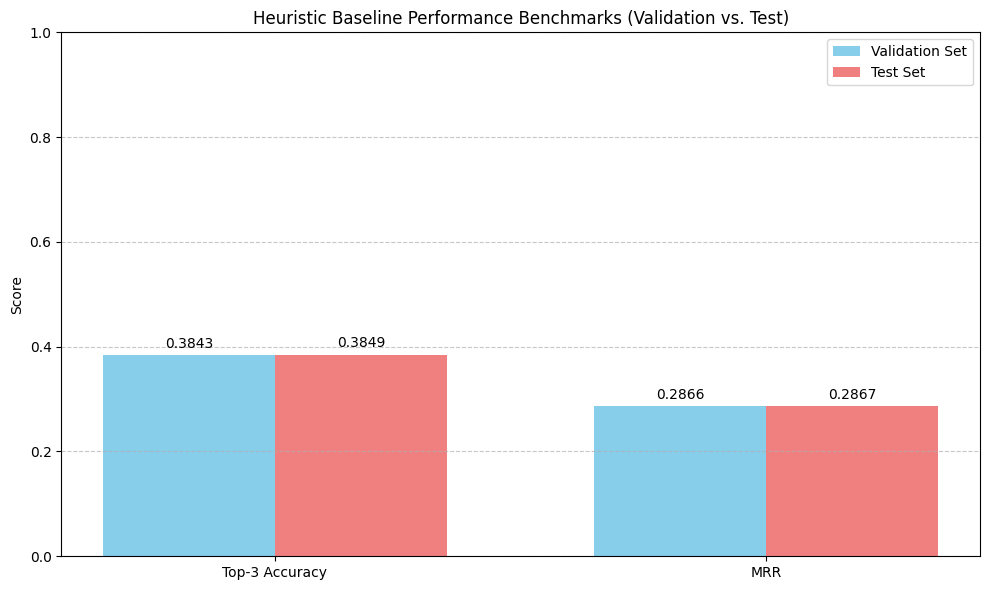

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data for plotting
metrics = ['Top-3 Accuracy', 'MRR']
val_scores = [val_top3, val_mrr]
test_scores = [test_top3, test_mrr]

x = np.arange(len(metrics))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 6))

rects1 = ax.bar(x - width/2, val_scores, width, label='Validation Set', color='skyblue')
rects2 = ax.bar(x + width/2, test_scores, width, label='Test Set', color='lightcoral')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Score')
ax.set_title('Heuristic Baseline Performance Benchmarks (Validation vs. Test)')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

def autolabel(rects):
    """Attach a text label above each bar in *rects*, displaying its height."""
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()

# Save for your coursework report
#plt.savefig('baseline_performance_comparison.pdf')
plt.show()

##XGboost Model

In [ ]:
pip install xgboost --upgrade

In [ ]:
import xgboost as xgb
import numpy as np
from sklearn.preprocessing import LabelEncoder # Import LabelEncoder
import numpy as np
import xgboost as xgb

# =====================================================================
# 1. CREATE TRACKED LOCAL TARGET MAPPING FOR TRAINING SET
# =====================================================================
# Extract the unique classes that actually exist within the training set slice
unique_train_classes = np.unique(y_train_flat)

# Build a fast mapping dictionary: {Global_Encoded_ID : Dense_Training_ID}
train_to_dense_map = {global_id: dense_id for dense_id, global_id in enumerate(unique_train_classes)}

# Create the unbroken, strictly continuous array for XGBoost
y_train_dense = np.array([train_to_dense_map[val] for val in y_train_flat], dtype=int)


# =====================================================================
# 2. INTIALIZE AND FIT THE TRACKED CLASSIFIER
# =====================================================================
print(f"Training on {len(unique_train_classes)} unique classes present in the train split...")

xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=8,
    objective='multi:softprob',
    num_class=len(unique_train_classes),  # Matches unique training classes perfectly
    random_state=42,
    device="cuda",
    tree_method="hist"
)

xgb_model.fit(X_train_flat, y_train_dense)
print("XGBoost Training Complete with no inference errors!")

Training on 241 unique classes present in the train split...
XGBoost Training Complete with no inference errors!


In [ ]:
def evaluate_mapped_xgboost_model(X_flat_matrix, target_df, model, label_encoder, unique_train_classes):
    """
    Highly optimized evaluation function for the re-mapped XGBoost model.
    Pre-computes the LabelEncoder mappings to avoid nested-loop CPU overhead.
    """
    # 1. Predict raw probability arrays for ONLY the classes present during training (GPU accelerated)
    dense_probabilities = model.predict_proba(X_flat_matrix)

    # 2. Expand dimensions back to the global baseline size (Total number of classes C)
    total_global_classes = len(label_encoder.classes_)
    global_probabilities = np.zeros((len(target_df), total_global_classes))

    # Map back to their original slots
    for dense_id, global_id in enumerate(unique_train_classes):
        global_probabilities[:, global_id] = dense_probabilities[:, dense_id]

    # --- OPTIMIZATION: Pre-map all possible classes to completely remove scikit-learn from the loop ---
    # Creates a lightning-fast dictionary lookup: { integer_choice : encoded_token }
    all_classes = label_encoder.classes_
    encoded_classes = label_encoder.transform(all_classes)
    global_token_map = dict(zip(all_classes, encoded_classes))

    top_3_hits = 0
    reciprocal_ranks = []
    total_rows = len(target_df)

    if total_rows == 0:
        return 0.0, 0.0

    # 3. Match the index to the original DataFrame row
    for idx, row in enumerate(target_df.itertuples()):
        row_probs = global_probabilities[idx]

        # Rank global class tokens from highest predicted probability to lowest
        ranked_encoded_classes = np.argsort(row_probs)[::-1]

        # --- OPTIMIZED MASKING STEP ---
        # Instead of calling .transform inside a loop, we do a rapid dictionary lookup
        current_legal_encoded_set = set()
        for i in range(len(row.legal_moves)):
            if i in global_token_map:
                current_legal_encoded_set.add(global_token_map[i])

        # Filter predicted classes instantly using pure Python set checks
        legal_predictions = [
            token for token in ranked_encoded_classes
            if token in current_legal_encoded_set
        ]

        # Isolate Top-3 valid choices
        top_3_predictions = legal_predictions[:3]

        # Find the global encoded ID of what the expert actually chose using our fast map
        # If the expert's choice isn't in our encoder tracking, we default to -1 (automatic miss)
        actual_expert_encoded = global_token_map.get(row.chosen_idx, -1)

        # Calculate Top-3 Accuracy
        if actual_expert_encoded in top_3_predictions:
            top_3_hits += 1

        # Calculate Mean Reciprocal Rank (MRR)
        if actual_expert_encoded in legal_predictions:
            rank = legal_predictions.index(actual_expert_encoded) + 1
            reciprocal_ranks.append(1.0 / rank)
        else:
            reciprocal_ranks.append(0.0)

    # Compute final averages
    top_3_acc = top_3_hits / total_rows
    mrr = np.mean(reciprocal_ranks)

    return top_3_acc, mrr

# =====================================================================
# EXECUTE XGBOOST EVALUATION
# =====================================================================

# Evaluate on Validation Features
xgb_val_top3, xgb_val_mrr = evaluate_mapped_xgboost_model(X_val_flat, val_df, xgb_model, le,unique_train_classes)
print(f"--- XGBoost Validation Metrics ---")
print(f"Validation Top-3 Accuracy : {xgb_val_top3:.4f}")
print(f"Validation MRR           : {xgb_val_mrr:.4f}\n")

# Evaluate on Test Features
xgb_test_top3, xgb_test_mrr = evaluate_mapped_xgboost_model(X_test_flat, test_df, xgb_model, le,unique_train_classes)
print(f"--- XGBoost Test Metrics ---")
print(f"Test Top-3 Accuracy       : {xgb_test_top3:.4f}")
print(f"Test MRR                  : {xgb_test_mrr:.4f}")

/usr/local/lib/python3.12/dist-packages/xgboost/core.py:751: UserWarning: [13:19:30] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


--- XGBoost Validation Metrics ---
Validation Top-3 Accuracy : 0.5426
Validation MRR           : 0.4839

--- XGBoost Test Metrics ---
Test Top-3 Accuracy       : 0.5434
Test MRR                  : 0.4838


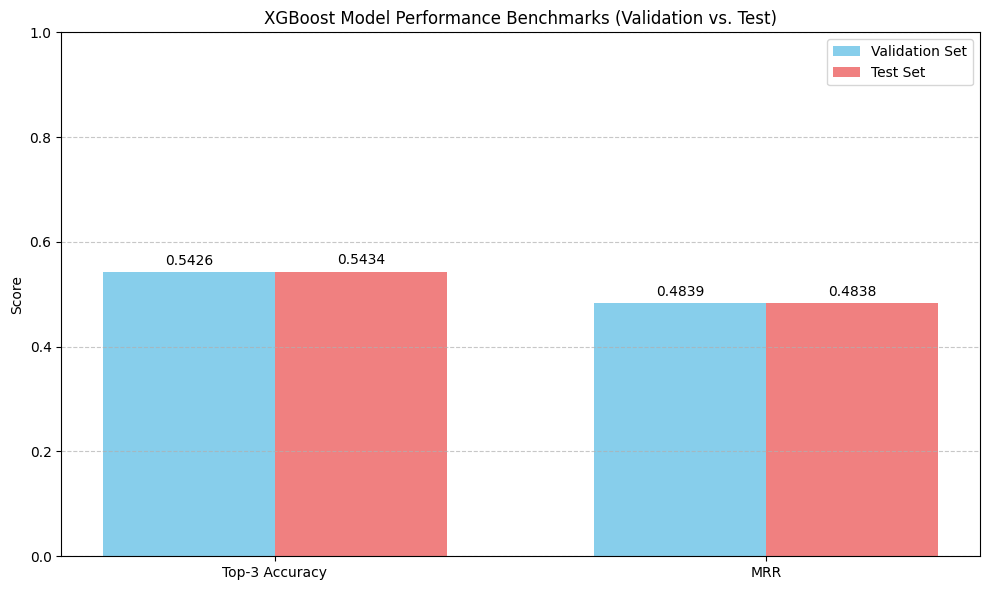

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data for plotting
metrics = ['Top-3 Accuracy', 'MRR']
val_scores = [xgb_val_top3, xgb_val_mrr]
test_scores = [xgb_test_top3, xgb_test_mrr]

x = np.arange(len(metrics))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 6))

rects1 = ax.bar(x - width/2, val_scores, width, label='Validation Set', color='skyblue')
rects2 = ax.bar(x + width/2, test_scores, width, label='Test Set', color='lightcoral')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Score')
ax.set_title('XGBoost Model Performance Benchmarks (Validation vs. Test)')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

def autolabel(rects):
    "Attach a text label above each bar in *rects*, displaying its height."
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.4f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()

# Save for your coursework report
#plt.savefig('xgb_performance_comparison.pdf')
plt.show()

In [ ]:
import numpy as np

# 1. Get raw probabilities from the xgb_model for the test set
dense_probabilities = xgb_model.predict_proba(X_test_flat)

# Map dense_probabilities back to the full global class space (all possible chosen_idx values)
total_global_original_chosen_idx_values = len(le.classes_)
global_probabilities = np.zeros((len(test_df), total_global_original_chosen_idx_values))

for dense_id, global_id in enumerate(unique_train_classes):
    global_probabilities[:, global_id] = dense_probabilities[:, dense_id]

# Initialize rank tracking
ranks = []

# Iterate through test_df to calculate the rank of the chosen_idx for each row
for idx, row in enumerate(test_df.itertuples()):
    row_probs = global_probabilities[idx]

    # Get the predicted encoded classes, ranked by probability
    ranked_encoded_classes = np.argsort(row_probs)[::-1]

    # Convert these encoded classes back to their original `chosen_idx` integer values
    ranked_original_chosen_idx_values = le.inverse_transform(ranked_encoded_classes)

    # MASKING STEP: Filter predicted original `chosen_idx` values based on actual legal moves
    legal_predicted_original_chosen_idx_values = []
    num_actual_legal_moves_for_this_row = len(row.legal_moves)

    for predicted_original_chosen_idx in ranked_original_chosen_idx_values:
        # Check if the predicted `original_chosen_idx` is a valid index into `row.legal_moves`
        if 0 <= predicted_original_chosen_idx < num_actual_legal_moves_for_this_row:
            legal_predicted_original_chosen_idx_values.append(predicted_original_chosen_idx)

    # The expert's actual chosen_idx for this row
    actual_expert_chosen_idx = row.chosen_idx

    # Find the rank of the expert's choice within the legal predictions
    current_rank = 0
    found_expert_choice = False
    if actual_expert_chosen_idx in legal_predicted_original_chosen_idx_values:
        current_rank = legal_predicted_original_chosen_idx_values.index(actual_expert_chosen_idx) + 1
        found_expert_choice = True

    if found_expert_choice:
        ranks.append(current_rank)
    else:
        # If the expert's choice was not found among the legal predictions,
        # assign a rank greater than 3 to ensure it falls into 'Rank 4+'
        ranks.append(999) # Placeholder for ranks > 3

ranks = np.array(ranks)

# 3. Calculate Counts
rank_1 = np.sum(ranks == 1)
rank_2 = np.sum(ranks == 2)
rank_3 = np.sum(ranks == 3)
rank_rest = np.sum(ranks > 3)

# 4. Calculate True vs False Predictions (Top-3 Accuracy logic)
true_preds = rank_1 + rank_2 + rank_3
false_preds = rank_rest

# 5. Display Results
print("--- Detailed Rank Breakdown for XGBoost Model (Test Set) ---")
print(f"Total evaluated rows: {len(ranks)}")
print(f"Rank 1: {rank_1} ({rank_1/len(ranks):.2%})")
print(f"Rank 2: {rank_2} ({rank_2/len(ranks):.2%})")
print(f"Rank 3: {rank_3} ({rank_3/len(ranks):.2%})")
print(f"Rank 4+: {rank_rest} ({rank_rest/len(ranks):.2%})")
print("\n--- Summary Performance for XGBoost Model (Test Set) ---")
print(f"True Predictions (Top-3): {true_preds} ({true_preds/len(ranks):.2%})")
print(f"False Predictions (Rank 4+): {false_preds} ({false_preds/len(ranks):.2%})")

--- Detailed Rank Breakdown for XGBoost Model (Test Set) ---
Total evaluated rows: 131274
Rank 1: 44458 (33.87%)
Rank 2: 16472 (12.55%)
Rank 3: 10399 (7.92%)
Rank 4+: 59945 (45.66%)

--- Summary Performance for XGBoost Model (Test Set) ---
True Predictions (Top-3): 71329 (54.34%)
False Predictions (Rank 4+): 59945 (45.66%)


##Proposed MLP

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np

# Set random seeds for strict academic reproducibility
torch.manual_seed(42)
np.random.seed(42)

# =====================================================================
# 1. PYTORCH DATASETS DEFINITION
# =====================================================================
class BackgammonDataset(Dataset):
    """Converts flat feature matrices and labels into PyTorch Tensors."""
    def __init__(self, X_flat, y_labels):
        # Convert features to float tensors, labels to long integers
        self.X = torch.tensor(X_flat, dtype=torch.float32)
        self.y = torch.tensor(y_labels, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create standard Mini-Batch DataLoaders
input_dim = X_train_flat.shape[1]
output_dim = len(le.classes_)  # Number of global distinct classes (C)

train_dataset = BackgammonDataset(X_train_flat, y_train_flat)
val_dataset = BackgammonDataset(X_val_flat, y_val_flat)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

In [ ]:
# =====================================================================
# 2. MODEL ARCHITECTURE (PROPOSED MLP)
# =====================================================================
class ProposedMLP(nn.Module):
    """
    A Deep Feedforward Neural Network architecture designed to capture
    hierarchical, non-linear relationships across Backgammon board slots.
    """
    def __init__(self, input_size, num_classes):
        super(ProposedMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 1024),
            nn.ReLU(),
            nn.Dropout(0.2),            # Prevents co-adaptation / overfitting
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes) # Raw logits output (No Softmax needed for CrossEntropyLoss)
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
# Check for CUDA (GPU) availability
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

mlp_model = ProposedMLP(input_size=input_dim, num_classes=output_dim)
mlp_model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(mlp_model.parameters(), lr=0.0005)

Using device: cuda


In [ ]:
# =====================================================================
# 3. TRAINING LOOP WITH LOSS MONITORING
# =====================================================================
num_epochs = 15
print("Commencing PyTorch MLP Training Loop...")

for epoch in range(num_epochs):
    mlp_model.train()
    running_train_loss = 0.0

    for batch_X, batch_y in train_loader:
        # Move tensors to the correct device
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()
        predictions = mlp_model(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * batch_X.size(0)

    # Calculate Epoch Validation Loss to track convergence curves
    mlp_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for val_X, val_y in val_loader:
            # Move tensors to the correct device
            val_X = val_X.to(device)
            val_y = val_y.to(device)

            val_preds = mlp_model(val_X)
            v_loss = criterion(val_preds, val_y)
            running_val_loss += v_loss.item() * val_X.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset)
    epoch_val_loss = running_val_loss / len(val_dataset)

    print(f"Epoch [{epoch+1:02d}/{num_epochs}] -> Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

print("PyTorch Deep Learning Optimization Complete!")

Commencing PyTorch MLP Training Loop...
Epoch [01/15] -> Train Loss: 2.5841 | Val Loss: 2.4574
Epoch [02/15] -> Train Loss: 2.4363 | Val Loss: 2.3749
Epoch [03/15] -> Train Loss: 2.3758 | Val Loss: 2.3249
Epoch [04/15] -> Train Loss: 2.3411 | Val Loss: 2.3049
Epoch [05/15] -> Train Loss: 2.3167 | Val Loss: 2.2795
Epoch [06/15] -> Train Loss: 2.3013 | Val Loss: 2.2691
Epoch [07/15] -> Train Loss: 2.2885 | Val Loss: 2.2557
Epoch [08/15] -> Train Loss: 2.2789 | Val Loss: 2.2451
Epoch [09/15] -> Train Loss: 2.2710 | Val Loss: 2.2429
Epoch [10/15] -> Train Loss: 2.2651 | Val Loss: 2.2415
Epoch [11/15] -> Train Loss: 2.2605 | Val Loss: 2.2333
Epoch [12/15] -> Train Loss: 2.2557 | Val Loss: 2.2272
Epoch [13/15] -> Train Loss: 2.2523 | Val Loss: 2.2278
Epoch [14/15] -> Train Loss: 2.2488 | Val Loss: 2.2317
Epoch [15/15] -> Train Loss: 2.2474 | Val Loss: 2.2231
PyTorch Deep Learning Optimization Complete!


In [ ]:
def evaluate_pytorch_mlp(X_flat_matrix, target_df, model, label_encoder):
    """
    Computes rigorous Top-3 Accuracy and MRR metrics for the PyTorch MLP
    by masking illegal outputs at a turn-by-turn row granularity.
    """
    model.eval()

    # 1. Convert input data matrix to tensor and compute forward pass logits
    # Fix: Move X_tensor to the same device as the model
    X_tensor = torch.tensor(X_flat_matrix, dtype=torch.float32).to(device)
    with torch.no_grad():
        logits = model(X_tensor)
        # Apply Softmax to translate raw neuron logits into probabilities
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()

    top_3_hits = 0
    reciprocal_ranks = []
    total_rows = len(target_df)

    if total_rows == 0:
        return 0.0, 0.0

    # 2. Align probability matrix indices to original dataframe rows
    for idx, row in enumerate(target_df.itertuples()):
        row_probs = probabilities[idx]

        # Rank global class tokens (original chosen_idx values) from highest predicted probability to lowest
        # ranked_encoded_classes gives the indices of the highest probabilities
        ranked_encoded_classes = np.argsort(row_probs)[::-1]

        # Decode these encoded class indices back to their original numerical 'chosen_idx' values.
        # These are the model's predicted 'chosen_idx' values, ranked.
        ranked_predicted_chosen_idx_values = label_encoder.inverse_transform(ranked_encoded_classes)

        # MASKING STEP: Filter predicted chosen_idx values that are valid indices for the actual legal moves
        # For each predicted 'chosen_idx', get the actual move sequence from `row.legal_moves` if the index is valid.
        ranked_legal_move_sequences = []
        num_legal_moves_for_this_row = len(row.legal_moves)

        for predicted_chosen_idx in ranked_predicted_chosen_idx_values:
            # Check if the predicted 'chosen_idx' is a valid index into the current row's legal_moves list.
            if 0 <= predicted_chosen_idx < num_legal_moves_for_this_row:
                ranked_legal_move_sequences.append(row.legal_moves[predicted_chosen_idx])

        # Extract top 3 valid options (actual move sequences)
        top_3_predictions = ranked_legal_move_sequences[:3]

        # Extract what the expert actually played (this is an actual move sequence)
        actual_expert_move = row.legal_moves[row.chosen_idx]

        # Track Top-3 Metrics
        if actual_expert_move in top_3_predictions:
            top_3_hits += 1

        # Track Reciprocal Rank Metrics
        if actual_expert_move in ranked_legal_move_sequences:
            rank = ranked_legal_move_sequences.index(actual_expert_move) + 1
            reciprocal_ranks.append(1.0 / rank)
        else:
            reciprocal_ranks.append(0.0)

    # Compute final averages across splits
    top_3_acc = top_3_hits / total_rows
    mrr = np.mean(reciprocal_ranks)

    return top_3_acc, mrr


# =====================================================================
# EXECUTE MLP PERFORMANCE BENCHMARKS
# =====================================================================

# Compute validation metrics
mlp_val_top3, mlp_val_mrr = evaluate_pytorch_mlp(X_val_flat, val_df, mlp_model, le)
print(f"--- PyTorch MLP Validation Metrics ---")
print(f"Validation Top-3 Accuracy : {mlp_val_top3:.4f}")
print(f"Validation MRR           : {mlp_val_mrr:.4f}\n")

# Compute test metrics
mlp_test_top3, mlp_test_mrr = evaluate_pytorch_mlp(X_test_flat, test_df, mlp_model, le)
print(f"--- PyTorch MLP Test Metrics ---")
print(f"Test Top-3 Accuracy       : {mlp_test_top3:.4f}")
print(f"Test MRR                  : {mlp_test_mrr:.4f}")

--- PyTorch MLP Validation Metrics ---
Validation Top-3 Accuracy : 0.5704
Validation MRR           : 0.5089

--- PyTorch MLP Test Metrics ---
Test Top-3 Accuracy       : 0.5728
Test MRR                  : 0.5096


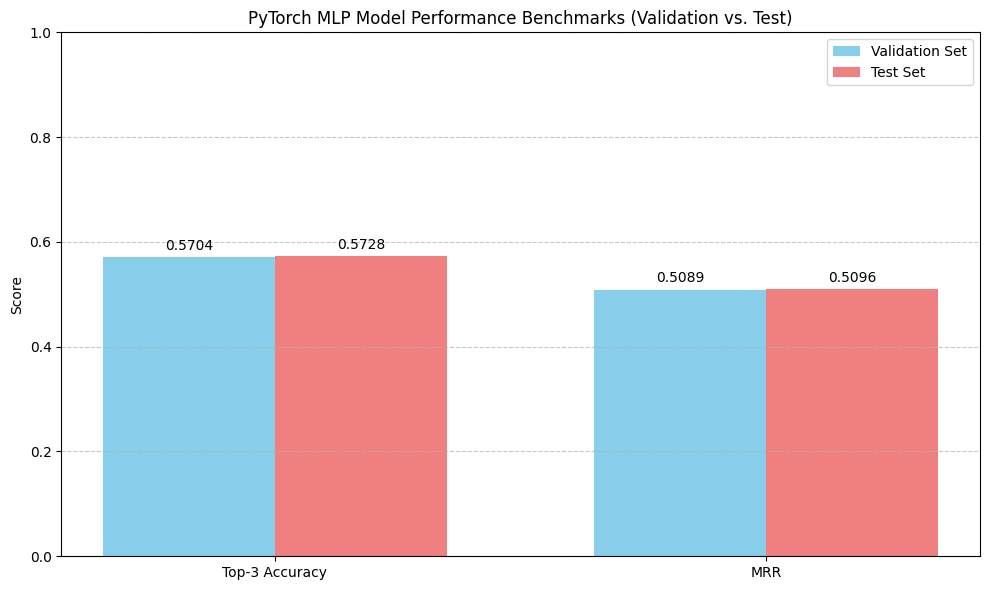

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_mlp_performance_comparison(val_top3, val_mrr, test_top3, test_mrr):
    # Data for plotting
    metrics = ['Top-3 Accuracy', 'MRR']
    val_scores = [val_top3, val_mrr]
    test_scores = [test_top3, test_mrr]

    x = np.arange(len(metrics))  # the label locations
    width = 0.35  # the width of the bars

    fig, ax = plt.subplots(figsize=(10, 6))

    rects1 = ax.bar(x - width/2, val_scores, width, label='Validation Set', color='skyblue')
    rects2 = ax.bar(x + width/2, test_scores, width, label='Test Set', color='lightcoral')

    # Add some text for labels, title and custom x-axis tick labels, etc.
    ax.set_ylabel('Score')
    ax.set_title('PyTorch MLP Model Performance Benchmarks (Validation vs. Test)')
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.set_ylim(0, 1.0)
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    def autolabel(rects):
        """Attach a text label above each bar in *rects*, displaying its height."""
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.4f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom')

    autolabel(rects1)
    autolabel(rects2)

    fig.tight_layout()
    plt.show()

# Call the plotting function with the MLP metrics
plot_mlp_performance_comparison(mlp_val_top3, mlp_val_mrr, mlp_test_top3, mlp_test_mrr)

#5) Evaluation of all models top-3 accuracies and Mrr

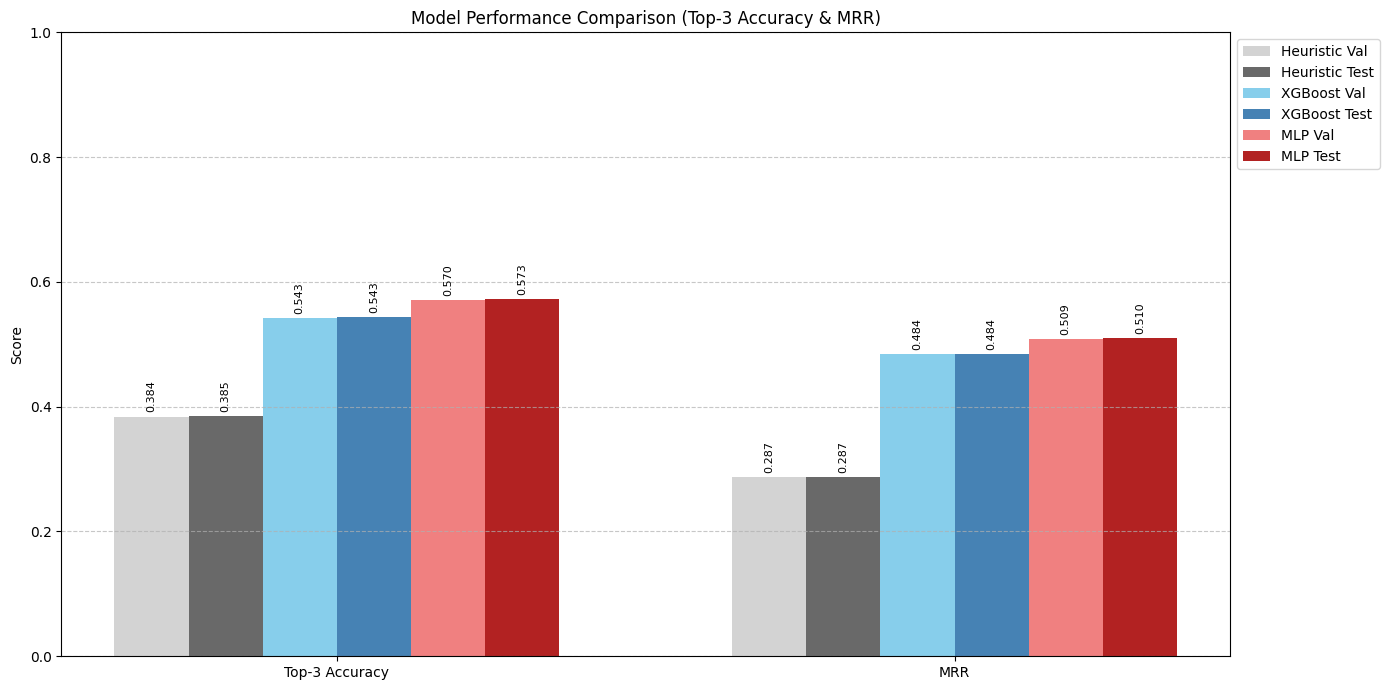

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data for plotting
metrics_labels = ['Top-3 Accuracy', 'MRR']

# Collect scores for all models (Validation and Test)
# Heuristic Baseline scores (assuming 'val_top3', 'val_mrr', 'test_top3', 'test_mrr' are available)
heuristic_val = [val_top3, val_mrr]
heuristic_test = [test_top3, test_mrr]

# XGBoost scores (assuming 'xgb_val_top3', 'xgb_val_mrr', 'xgb_test_top3', 'xgb_test_mrr' are available)
xgb_val = [xgb_val_top3, xgb_val_mrr]
xgb_test = [xgb_test_top3, xgb_test_mrr]

# MLP scores (assuming 'mlp_val_top3', 'mlp_val_mrr', 'mlp_test_top3', 'mlp_test_mrr' are available)
mlp_val = [mlp_val_top3, mlp_val_mrr]
mlp_test = [mlp_test_top3, mlp_test_mrr]

# Number of metric types (2: Top-3 Accuracy, MRR)
x = np.arange(len(metrics_labels))

# Number of models (3: Heuristic, XGBoost, MLP) * 2 (Val/Test) = 6 bars per metric group
bar_width = 0.12 # Adjust width based on number of bars

fig, ax = plt.subplots(figsize=(14, 7))

# Position for each set of bars
# Heuristic Val/Test
ax.bar(x - 2.5*bar_width, heuristic_val, bar_width, label='Heuristic Val', color='lightgray')
ax.bar(x - 1.5*bar_width, heuristic_test, bar_width, label='Heuristic Test', color='dimgray')

# XGBoost Val/Test
ax.bar(x - 0.5*bar_width, xgb_val, bar_width, label='XGBoost Val', color='skyblue')
ax.bar(x + 0.5*bar_width, xgb_test, bar_width, label='XGBoost Test', color='steelblue')

# MLP Val/Test
ax.bar(x + 1.5*bar_width, mlp_val, bar_width, label='MLP Val', color='lightcoral')
ax.bar(x + 2.5*bar_width, mlp_test, bar_width, label='MLP Test', color='firebrick')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison (Top-3 Accuracy & MRR)')
ax.set_xticks(x) # Set tick locations
ax.set_xticklabels(metrics_labels) # Set tick labels
ax.set_ylim(0, 1.0) # Scores are typically between 0 and 1
ax.legend(loc='upper left', bbox_to_anchor=(1,1))
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Function to add labels on top of the bars
def autolabel(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3), # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', rotation=90, fontsize=8)

# Apply autolabel to all bar sets
autolabel(ax.containers[0])
autolabel(ax.containers[1])
autolabel(ax.containers[2])
autolabel(ax.containers[3])
autolabel(ax.containers[4])
autolabel(ax.containers[5])

fig.tight_layout()
plt.show()

#6) Testing all the models to predict top 3 moves for a provided: Borad,Player and Dice. as real world data not from the dataset samples

In [ ]:
import torch
import numpy as np
import pandas as pd
from copy import deepcopy
def predict_top_moves(board, dice, player_str):

    print(f"\n--- Predicting Top Moves for {player_str} with Dice {dice} ---")
    print(f"Current Board State: {board}")

    # 1. Generate all legal moves for the current state
    legal_moves_for_turn = generate_legal_moves(board, player_str, dice)

    if not legal_moves_for_turn:
        print("No legal moves available for this board state and dice roll.")
        return

    # --- Heuristic Model --- #
    print("\n--- Heuristic Model Predictions ---")
    heuristic_predictions = get_baseline_top_3(board, player_str, legal_moves_for_turn)
    for i, move in enumerate(heuristic_predictions):
        print(f"  Rank {i+1}: {move}")

    # --- Prepare input for ML models (XGBoost, MLP) ---
    # Normalize player to integer (0 for P1, 1 for P2)
    player_int = 0 if player_str == 'P1' else 1

    # Prepare features for ML models: board (28) + player (1) + dice (2) = 31 features
    # Ensure dice is a list of integers for consistent input
    dice_list = list(dice)

    # Combine into a single feature vector
    X_single_input = np.array(board + [player_int] + dice_list, dtype=np.float32).reshape(1, -1)

    # --- XGBoost Model --- #
    print("\n--- XGBoost Model Predictions ---")
    # Predict raw probabilities from the XGBoost model
    dense_probabilities = xgb_model.predict_proba(X_single_input)

    # Map dense probabilities back to the full global class space
    total_global_classes = len(le.classes_)
    global_probabilities = np.zeros(total_global_classes)
    for dense_id, global_id in enumerate(unique_train_classes):
        global_probabilities[global_id] = dense_probabilities[0, dense_id] # [0, dense_id] because X_single_input is 1 row

    # Rank global class tokens from highest predicted probability to lowest
    ranked_encoded_classes = np.argsort(global_probabilities)[::-1]

    # Decode these encoded class indices back to their original 'chosen_idx' integer values
    ranked_original_chosen_idx_values = le.inverse_transform(ranked_encoded_classes)

    # Filter predictions based on actual legal moves and get top 3
    xgb_predictions = []
    for predicted_original_chosen_idx in ranked_original_chosen_idx_values:
        if 0 <= predicted_original_chosen_idx < len(legal_moves_for_turn):
            # Append the actual move sequence from legal_moves_for_turn
            xgb_predictions.append(legal_moves_for_turn[predicted_original_chosen_idx])
        if len(xgb_predictions) == 3: # Only need top 3
            break

    for i, move in enumerate(xgb_predictions):
        print(f"  Rank {i+1}: {move}")

    # --- MLP Model --- #
    print("\n--- MLP Model Predictions ---")
    mlp_model.eval() # Set model to evaluation mode
    X_tensor = torch.tensor(X_single_input, dtype=torch.float32).to(device)

    with torch.no_grad():
        logits = mlp_model(X_tensor)
        probabilities = torch.softmax(logits, dim=1).cpu().numpy().flatten()

    # Rank global class tokens from highest predicted probability to lowest
    ranked_encoded_classes_mlp = np.argsort(probabilities)[::-1]
    ranked_original_chosen_idx_values_mlp = le.inverse_transform(ranked_encoded_classes_mlp)

    # Filter predictions based on actual legal moves and get top 3
    mlp_predictions = []
    for predicted_original_chosen_idx in ranked_original_chosen_idx_values_mlp:
        if 0 <= predicted_original_chosen_idx < len(legal_moves_for_turn):
            mlp_predictions.append(legal_moves_for_turn[predicted_original_chosen_idx])
        if len(mlp_predictions) == 3:
            break

    for i, move in enumerate(mlp_predictions):
        print(f"  Rank {i+1}: {move}")






--- Predicting Top Moves for P1 with Dice (6, 6) ---
Current Board State: [-1, 0, 0, 0, 0, 5, 0, 3, -1, 0, 0, -5, 5, 0, 0, 0, -3, 0, -5, 0, 0, 0, 0, 2, 0, 0, 0, 0]

--- Heuristic Model Predictions ---
  Rank 1: [(13, 7), (13, 7), (7, 1), (7, 1)]
  Rank 2: [(13, 7), (8, 2), (8, 2), (7, 1)]
  Rank 3: [(13, 7), (8, 2), (8, 2), (8, 2)]

--- XGBoost Model Predictions ---
  Rank 1: [(24, 18), (24, 18), (13, 7), (13, 7)]
  Rank 2: [(24, 18), (13, 7), (13, 7), (7, 1)]
  Rank 3: [(24, 18), (24, 18), (13, 7), (8, 2)]

--- MLP Model Predictions ---
  Rank 1: [(24, 18), (24, 18), (13, 7), (13, 7)]
  Rank 2: [(24, 18), (24, 18), (13, 7), (7, 1)]
  Rank 3: [(13, 7), (13, 7), (13, 7), (13, 7)]


In [ ]:
# # Test with a specific board state from the notebook where legal moves are known to exist
test_board_example = [-1,0,0,0,0,5,0,3,-1,0,0,-5,5,0,0,0,-3,0,-5,0,0,0,0,2,0,0,0,0]
test_dice_example = (6,6)
test_player_example = "P1"
predict_top_moves(test_board_example, test_dice_example, test_player_example)
